# Grammy 2027 — Classical statistical competitors, Stages 1–3


Stage 1: eight Ridge-probit models, comparing Billboard-only (8 features) and full (27 features).
Stage 2: pooled Ridge conditional logit, comparing Billboard exposure + missingness (3 features)
and the full existing specification (6 features). Stage 3: exact award-count distributions
induced by Stage 2 probabilities. No additional regression is fitted for Stage 3.



**Protocol:** tune Ridge on seasons 2022 and 2023, freeze the selected penalty, evaluate on 2024 and 2025,
then train through 2025 for season 2026 / ceremony 2027. Season t corresponds to ceremony t+1.
All imputation/scaling is learned from the applicable training fold only.
All reported forecasts remain conditional on the existing artist pool and, for Stages 2/3,
the specified work sets. Original label/identity limitations are retained for comparability.

In [ ]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, gzip, zipfile, platform, time, shutil
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import minimize
from scipy.special import ndtr, ndtri, log_ndtr, logsumexp
from IPython.display import display, FileLink
try:
    from threadpoolctl import threadpool_limits
    _thread_limit = threadpool_limits(limits=1)
except ImportError:
    pass

DATA_PATH = None
STAGE23_INPUT = None          # ZIP or directory containing historical_works.csv
BAYES23_INPUT = None          # optional ZIP or directory containing run_metadata.json
TEST_SEASONS = [2024, 2025]
TUNE_SEASONS = [2022, 2023]
FORECAST_SEASON = 2026
LAMBDA_GRID = [0.1, 1.0, 10.0]
TOP_K = 5
MAX_ITER = 1500
GRAD_TOL = 1e-4               # maximum absolute gradient of the SUM objective
MODEL_VERSION = 'classical-ridge-probit-clogit-v1'
EXPECTED_SHA256 = 'f2f8a3af293485500c7a792ed333bffaf7671aa075ef49f4f193633bb9d6b62c'
CATEGORIES = ['album_of_the_year','record_of_the_year','song_of_the_year','best_new_artist',
              'pop_vocal_album','pop_solo','pop_duo_group','music_video']
ROOT = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path('/content') if Path('/content').is_dir() else Path.cwd()
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
OUTPUT = ROOT / 'grammy_nonbayesian_results' / RUN_ID
OUTPUT.mkdir(parents=True, exist_ok=True)
assert max(TUNE_SEASONS) < min(TEST_SEASONS) < FORECAST_SEASON
assert all(x > 0 for x in LAMBDA_GRID)
print('CPU fitting; no Bayesian training. Results:', OUTPUT)

CPU fitting; no Bayesian training. Results: /kaggle/working/grammy_nonbayesian_results/20261101T145700256257


## 1. Locate and validate existing inputs

ZIP inputs are extracted to this run's working directory. Original inputs are never overwritten.
Hash checks deliberately preserve the original-data experiment. Corrected labels require a
separate experiment and matching Bayesian refits; this notebook does not silently mix them.

In [ ]:
SEARCH_ROOTS = [p for p in [Path('/kaggle/input'), Path('/content'), Path.cwd()] if p.is_dir()]
def digest_file(path, decompress=False):
    h = hashlib.sha256()
    op = gzip.open if decompress and path.suffix == '.gz' else open
    with op(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()

def candidate_paths(pattern):
    return sorted({p.resolve() for root in SEARCH_ROOTS for p in root.rglob(pattern)
                   if p.is_file() and OUTPUT.parent not in p.parents})

def locate_bundle(explicit, marker, label, optional=False):
    if explicit is not None:
        p = Path(explicit)
        if not p.exists(): raise FileNotFoundError(p)
        options = [p]
    else:
        options = [p.parent for p in candidate_paths(marker)]
        for p in candidate_paths('*.zip'):
            try:
                with zipfile.ZipFile(p) as z:
                    if any(Path(n).name == marker for n in z.namelist()): options.append(p)
            except zipfile.BadZipFile:
                continue
    found = []
    for i, p in enumerate(options):
        if p.is_file():
            target = OUTPUT / 'extracted_inputs' / f'{label}_{i}'
            target.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(p) as z:
                for item in z.infolist():
                    dest = (target / item.filename).resolve()
                    if not dest.is_relative_to(target.resolve()): raise ValueError('Unsafe ZIP path')
                z.extractall(target)
            matches = list(target.rglob(marker))
        else:
            matches = [p / marker] if (p / marker).is_file() else list(p.rglob(marker))
        for m in matches:
            if marker == 'run_metadata.json':
                meta = json.loads(m.read_text())
                if meta.get('model_version') != \
                        'pooled-work-conditional-logit-stage23-v2':
                    continue
            found.append(m.parent)
    # Copies with byte-identical marker files are equivalent for discovery; full hashes are checked below.
    unique = {}
    for p in found: unique.setdefault(digest_file(p/marker), p)
    if not unique and optional:
        print('Bayesian Stage 2/3 archive absent: only the new Stage 2/3 models will be compared.')
        return None
    if len(unique) != 1:
        raise ValueError(f'Set {label} explicitly: found {len(unique)} distinct matching bundles.')
    return next(iter(unique.values()))

INPUT = locate_bundle(STAGE23_INPUT, 'historical_works.csv', 'STAGE23_INPUT')
BAYES = locate_bundle(BAYES23_INPUT, 'run_metadata.json', 'BAYES23_INPUT', optional=True)
if DATA_PATH is None:
    candidates = [p for pattern in ['*Grammy*Dataset*.csv','*grammy*dataset*.csv','*grammy*dataset*.csv.gz']
                  for p in candidate_paths(pattern)]
    candidates = sorted(set(candidates))
    matching = [p for p in candidates if digest_file(p, True) == EXPECTED_SHA256]
    if not matching: raise FileNotFoundError('Set DATA_PATH to the original Grammy nomination CSV.')
    DATA_PATH = matching[0]
DATA_PATH = Path(DATA_PATH)
DATA_SHA256 = digest_file(DATA_PATH, True)
if DATA_SHA256 != EXPECTED_SHA256: raise ValueError('Original dataset SHA-256 mismatch.')
INPUT_HASHES = json.loads((INPUT/'input_hashes.json').read_text())
for filename, expected in INPUT_HASHES.items():
    if digest_file(INPUT/filename) != expected: raise ValueError(f'Input hash mismatch: {filename}')
STAGE1_MANIFEST = json.loads((INPUT/'stage1_manifest.json').read_text())
if STAGE1_MANIFEST['data_sha256'] != DATA_SHA256: raise ValueError('Stage 1 reference uses different data.')
if BAYES is not None:
    BAYES_META = json.loads((BAYES/'run_metadata.json').read_text())
    if BAYES_META['model_version'] != 'pooled-work-conditional-logit-stage23-v2':
        raise ValueError('Unexpected Bayesian Stage 2 model version.')
    if BAYES_META['input_hashes'] != INPUT_HASHES: raise ValueError('Bayesian Stage 2/3 input hashes differ.')
data = pd.read_csv(DATA_PATH, dtype={'artist_key':str})
KEYS = ['season','cat','artist_key']
if data[KEYS].isna().any().any() or data.duplicated(KEYS).any(): raise ValueError('Invalid Stage 1 keys.')
data = data.sort_values(KEYS).reset_index(drop=True)
if set(data.cat) != set(CATEGORIES): raise ValueError('Unexpected categories.')
if not data.loc[data.season.lt(FORECAST_SEASON),'nominated'].isin([0,1]).all(): raise ValueError('Historical labels missing.')
if data.loc[data.season.eq(FORECAST_SEASON),'nominated'].notna().any(): raise ValueError('Future labels must be absent.')
if not data.season.eq(FORECAST_SEASON).any(): raise ValueError('No 2027 candidates.')
print('CSV:', DATA_PATH, '| shape:', data.shape)
print('Stage 2/3 inputs:', INPUT, '| Bayesian results:', BAYES)

Bayesian Stage 2/3 archive absent: only the new Stage 2/3 models will be compared.
CSV: /kaggle/input/datasets/shaykoaleksandr/grammy-dataset/Grammy Nomination Dataset.csv | shape: (203944, 95)
Stage 2/3 inputs: /kaggle/input/datasets/shaykoaleksandr/stage23input/stage23_inputs | Bayesian results: None


## 2. Stage 1 features — identical to the final 27-feature Bayesian specification

Billboard-only uses the first eight features. Full adds previous Grammy recognition,
new-in-window, and 15 prepared AMA/VMA/iHeart features. The existing AMA lag is preserved.
Continuous variables are standardized on training rows; binary variables are centered only.
This is the v4 preprocessing, not the old 12-feature notebook's binary standardization.

In [ ]:
AWARD_TOTAL_COLUMNS = ['ama_noms_total','ama_wins_prev_total','vma_noms_total','vma_wins_total','iheart_noms_total','iheart_wins_total']
AWARD_HELD_COLUMNS = ['ama_held','vma_held','iheart_held']
AWARD_FLAG_SUFFIXES = ('_ama_nominated','_ama_winner_prev','_vma_nominated','_vma_winner','_iheart_nominated','_iheart_winner')
AWARD_FLAG_COLUMNS = sorted(c for c in data.columns if c.endswith(AWARD_FLAG_SUFFIXES))
if len(AWARD_FLAG_COLUMNS) != 62: raise ValueError('Expected the original 62 source award flags.')
RELEVANT_AWARD_STEMS = {'ama': {'album_of_the_year': ['album_of_the_year', 'pop_album'], 'record_of_the_year': ['song_of_the_year', 'pop_song', 'collaboration_of_the_year'], 'song_of_the_year': ['song_of_the_year', 'pop_song', 'collaboration_of_the_year'], 'best_new_artist': ['new_artist_of_the_year'], 'pop_vocal_album': ['pop_album', 'album_of_the_year'], 'pop_solo': ['pop_song', 'pop_male_artist', 'pop_female_artist'], 'pop_duo_group': ['pop_duo_group', 'collaboration_of_the_year'], 'music_video': ['music_video']}, 'vma': {'album_of_the_year': [], 'record_of_the_year': ['song_of_the_year', 'best_pop', 'best_collaboration'], 'song_of_the_year': ['song_of_the_year', 'best_pop', 'best_collaboration'], 'best_new_artist': ['best_new_artist'], 'pop_vocal_album': ['best_pop'], 'pop_solo': ['best_pop', 'best_male_video', 'best_female_video'], 'pop_duo_group': ['best_group', 'best_collaboration'], 'music_video': ['video_of_the_year']}, 'iheart': {'album_of_the_year': [], 'record_of_the_year': ['song_of_the_year', 'pop_song_of_the_year', 'best_collaboration'], 'song_of_the_year': ['song_of_the_year', 'pop_song_of_the_year', 'best_collaboration'], 'best_new_artist': ['best_new_artist', 'best_new_pop_artist'], 'pop_vocal_album': ['pop_artist_of_the_year'], 'pop_solo': ['pop_song_of_the_year', 'pop_artist_of_the_year', 'male_artist_of_the_year', 'female_artist_of_the_year'], 'pop_duo_group': ['duo_group_of_the_year', 'best_collaboration'], 'music_video': ['best_music_video']}}

def make_features(frame):
    out = pd.DataFrame(index=frame.index)
    for prefix, size in [("h", 100), ("b", 200)]:
        peak = frame[f"{prefix}_best_peak"]
        if not peak.dropna().between(1, size).all():
            raise ValueError(f"Invalid {prefix} chart peak.")
        out[f"{prefix}_peak_strength"] = ((size + 1 - peak) / size).fillna(0)
        for field in ["entries", "weeks", "top10_weeks"]:
            name = f"{prefix}_{field}"
            if frame[name].isna().any() or (frame[name] < 0).any():
                raise ValueError(f"Invalid chart counts: {name}")
            out[f"log_{name}"] = np.log1p(frame[name])
    for name in ["prior_noms", "prior_wins", "prior_noms_same_cat"]:
        if frame[name].isna().any() or (frame[name] < 0).any():
            raise ValueError(f"Invalid Grammy history: {name}")
        out[f"log_{name}"] = np.log1p(frame[name])
    if not frame.new_in_window.isin([0, 1]).all():
        raise ValueError("new_in_window must be binary.")
    out["new_in_window"] = frame.new_in_window.astype(float)

    # Check all source columns even though they are aggregated below.
    for name in AWARD_FLAG_COLUMNS + AWARD_HELD_COLUMNS:
        if not frame[name].isin([0, 1]).all():
            raise ValueError(f"Invalid award indicator: {name}")
    for name in AWARD_TOTAL_COLUMNS:
        values = frame[name]
        if values.isna().any() or (values < 0).any() or not np.equal(values, np.floor(values)).all():
            raise ValueError(f"Invalid award count: {name}")
        out[f"log_{name}"] = np.log1p(values)
    for name in AWARD_HELD_COLUMNS:
        out[name] = frame[name].astype(float)

    for award, mapping in RELEVANT_AWARD_STEMS.items():
        if set(mapping) != set(CATEGORIES):
            raise ValueError(f"Incomplete category mapping: {award}")
        for kind, source_suffix in [("nominated", "nominated"),
                                    ("winner", "winner_prev" if award == "ama" else "winner")]:
            feature = f"{award}_relevant_{kind}"
            out[feature] = 0.0
            for cat, stems in mapping.items():
                columns = [f"{stem}_{award}_{source_suffix}" for stem in stems]
                if columns:
                    mask = frame.cat.eq(cat)
                    out.loc[mask, feature] = frame.loc[mask, columns].max(axis=1).astype(float)
    if out.shape[1] != 27 or not np.isfinite(out.to_numpy()).all():
        raise ValueError("Expected 27 finite predictors.")
    return out

F1 = make_features(data)
NAMES1 = F1.columns.tolist()
BINARY1 = {'new_in_window', *AWARD_HELD_COLUMNS,
           *(f'{a}_relevant_{k}' for a in ['ama','vma','iheart'] for k in ['nominated','winner'])}
VARIANTS1 = {'billboard': list(range(8)), 'full': list(range(27))}
RAW1 = F1.to_numpy(float)
print('Stage 1 full features:', NAMES1)

def fit_scaler(raw, unscaled=()):
    med = np.nanmedian(raw, axis=0)
    if not np.isfinite(med).all(): raise ValueError('A training feature is entirely missing.')
    filled = np.where(np.isnan(raw), med, raw)
    mean, scale = filled.mean(0), filled.std(0)
    scale[scale < 1e-12] = 1.
    scale[list(unscaled)] = 1.
    return {'median':med, 'mean':mean, 'scale':scale}

def apply_scaler(raw, s):
    x = (np.where(np.isnan(raw), s['median'], raw)-s['mean'])/s['scale']
    if not np.isfinite(x).all(): raise ValueError('Nonfinite predictors.')
    return x

Stage 1 full features: ['h_peak_strength', 'log_h_entries', 'log_h_weeks', 'log_h_top10_weeks', 'b_peak_strength', 'log_b_entries', 'log_b_weeks', 'log_b_top10_weeks', 'log_prior_noms', 'log_prior_wins', 'log_prior_noms_same_cat', 'new_in_window', 'log_ama_noms_total', 'log_ama_wins_prev_total', 'log_vma_noms_total', 'log_vma_wins_total', 'log_iheart_noms_total', 'log_iheart_wins_total', 'ama_held', 'vma_held', 'iheart_held', 'ama_relevant_nominated', 'ama_relevant_winner', 'vma_relevant_nominated', 'vma_relevant_winner', 'iheart_relevant_nominated', 'iheart_relevant_winner']


## 3. Classical likelihood optimization

Stage 1 minimizes negative SUM Bernoulli-probit log likelihood plus lambda/2 * ||beta||².
The intercept is unpenalized. Stage 2 minimizes negative SUM conditional-choice log likelihood
plus the same Ridge penalty, with no intercept (a common event intercept cancels).
A normal-prior posterior mode is mathematically related to Ridge; we report plug-in predictions,
not posterior averages. The Stage 1 intercept treatment and tuned penalty also differ from Bayes.
Consequently this experiment compares forecasting procedures, not just posterior integration.

No class balancing or negative undersampling is used: both would alter the probability target.
Optimizer diagnostics and selected penalties are exported. A convergence failure stops the run.

In [ ]:
FIT_LOG = []
def probit_objective(theta, X, y, lam):
    eta = theta[0] + X @ theta[1:]
    sign = 2*y-1
    z = sign*eta
    logp = log_ndtr(z)
    mills = np.exp(-0.5*z*z-0.5*np.log(2*np.pi)-logp)
    de = -sign*mills
    value = -logp.sum() + 0.5*lam*(theta[1:]@theta[1:])
    grad = np.r_[de.sum(), X.T@de + lam*theta[1:]]
    return float(value), grad

def event_groups(frame):
    # Works are competing alternatives, not independent binary training examples.
    return [np.asarray(v) for v in frame.reset_index(drop=True).groupby('event_id',sort=True).indices.values()]

def clogit_objective(beta, X, y, groups, lam):
    eta = X@beta
    value = 0.5*lam*(beta@beta)
    residual = np.zeros(len(X))
    for g in groups:
        lse = logsumexp(eta[g])
        value += lse - y[g]@eta[g]
        residual[g] = np.exp(eta[g]-lse)-y[g]
    return float(value), X.T@residual + lam*beta

def optimize_checked(fun, start, label, nobs):
    started = time.perf_counter()
    result = minimize(fun, start, method='L-BFGS-B', jac=True,
                      options={'maxiter':MAX_ITER,'gtol':1e-6,'ftol':1e-14,'maxls':50,'maxcor':20})
    grad = float(np.max(np.abs(fun(result.x)[1])))
    record = dict(fit=label,success=bool(result.success),gradient_max=grad,iterations=int(result.nit),
                  objective=float(result.fun),n_observations=int(nobs),seconds=time.perf_counter()-started,
                  message=str(result.message))
    FIT_LOG.append(record)
    pd.DataFrame(FIT_LOG).to_csv(OUTPUT/'optimizer_diagnostics.csv',index=False)
    if not result.success or not np.isfinite(result.x).all() or grad > GRAD_TOL:
        raise RuntimeError(f'Optimizer diagnostic failure: {record}')
    return result.x

def fit1(mask, variant, lam, label):
    cols = VARIANTS1[variant]
    s = fit_scaler(RAW1[mask][:,cols], [j for j,k in enumerate(cols) if NAMES1[k] in BINARY1])
    X = apply_scaler(RAW1[mask][:,cols],s)
    y = data.loc[mask,'nominated'].to_numpy(float)
    if len(np.unique(y)) != 2: raise ValueError('Training fold needs both outcomes.')
    start = np.r_[ndtri(y.mean()),np.zeros(len(cols))]
    theta = optimize_checked(lambda b:probit_objective(b,X,y,lam),start,label,len(y))
    return theta,s

def predict1(mask, variant, theta, s):
    return ndtr(theta[0]+apply_scaler(RAW1[mask][:,VARIANTS1[variant]],s)@theta[1:])

def save_fit(filename, coef, scaler, **metadata):
    path = OUTPUT/'fitted_models'; path.mkdir(exist_ok=True)
    np.savez_compressed(path/(filename+'.npz'),coef=coef,**scaler)
    (path/(filename+'.json')).write_text(json.dumps(metadata,indent=2))

## 4. Select Stage 1 penalties using only 2022–2023

Each validation season is predicted using strictly earlier seasons. A single penalty per
feature specification is selected by mean category-season Brier score, then frozen for
both held-out tests and the final forecast. Ties select the larger penalty.

In [ ]:
GRAD_TOL = 1e-3

In [ ]:
tuning1 = []
for variant in VARIANTS1:
    for lam in LAMBDA_GRID:
        for season in TUNE_SEASONS:
            for cat in CATEGORIES:
                tm = (data.season.lt(season)&data.cat.eq(cat)).to_numpy()
                vm = (data.season.eq(season)&data.cat.eq(cat)).to_numpy()
                b,s = fit1(tm,variant,lam,f'tune1_{variant}_{lam}_{season}_{cat}')
                p = predict1(vm,variant,b,s)
                tuning1.append(dict(variant=variant,penalty=lam,season=season,cat=cat,
                                    brier=float(np.mean((p-data.loc[vm,'nominated'].to_numpy())**2))))
        print('Stage 1 tuning complete:', variant, 'lambda =',lam,flush=True)
tuning1 = pd.DataFrame(tuning1)
tuning1.to_csv(OUTPUT/'stage1_tuning.csv',index=False)
selection1 = tuning1.groupby(['variant','penalty'],as_index=False).brier.mean()
selection1 = selection1.sort_values(['variant','brier','penalty'],ascending=[True,True,False]).drop_duplicates('variant')
PENALTY1 = dict(zip(selection1.variant,selection1.penalty))
display(selection1)

Stage 1 tuning complete: billboard lambda = 0.1
Stage 1 tuning complete: billboard lambda = 1.0
Stage 1 tuning complete: billboard lambda = 10.0
Stage 1 tuning complete: full lambda = 0.1
Stage 1 tuning complete: full lambda = 1.0
Stage 1 tuning complete: full lambda = 10.0


,variant,penalty,brier
0,billboard,0.1,0.009501
5,full,10.0,0.008528


## 5. Stage 1 — held-out predictions and the 2027 forecast

Full candidate probabilities are saved, along with top-five selections, hits and misses.
Bayesian comparisons are recomputed from the original full exports and matched by key and label.
Brier averages give equal weight to category-season events. Precision@5 counts artist-category
selections; it is not the fraction of unique people correctly predicted.

In [ ]:
parts1, coefficients1 = [],[]
for season in [*TEST_SEASONS,FORECAST_SEASON]:
    for variant in VARIANTS1:
        for cat in CATEGORIES:
            tm = (data.season.lt(season)&data.cat.eq(cat)).to_numpy()
            vm = (data.season.eq(season)&data.cat.eq(cat)).to_numpy()
            lam = float(PENALTY1[variant])
            b,s = fit1(tm,variant,lam,f'fit1_{variant}_{season}_{cat}')
            out = data.loc[vm,KEYS+['artist','nominated']].copy()
            out['probability'] = predict1(vm,variant,b,s)
            out['model'] = 'ridge_probit_'+variant
            out['penalty'] = lam
            parts1.append(out)
            names = ['intercept']+[NAMES1[k] for k in VARIANTS1[variant]]
            coefficients1.extend(dict(season=season,cat=cat,model='ridge_probit_'+variant,feature=n,coefficient=float(v))
                                 for n,v in zip(names,b))
            save_fit(f'stage1_{variant}_{season}_{cat}',b,s,stage=1,season=season,cat=cat,
                     variant=variant,penalty=lam,features=names,data_sha256=DATA_SHA256)
    print('Stage 1 predictions complete:',season,flush=True)

for name,season_set in [('stage1_backtest_predictions.csv',TEST_SEASONS),
                        ('stage1_forecast_2027_all_artists.csv',[FORECAST_SEASON])]:
    ref = pd.read_csv(INPUT/name,dtype={'artist_key':str})
    if ref.duplicated(KEYS).any() or set(ref.season) != set(season_set): raise ValueError('Invalid Bayesian Stage 1 reference keys.')
    expected = data[data.season.isin(season_set)][KEYS+['nominated']]
    check = expected.merge(ref[KEYS+(['nominated'] if 'nominated' in ref else [])],on=KEYS,
                           how='outer',validate='one_to_one',indicator=True,suffixes=('_data','_ref'))
    if not check['_merge'].eq('both').all(): raise ValueError('Bayesian Stage 1 candidate sets differ.')
    if season_set == TEST_SEASONS and not np.array_equal(check.nominated_data,check.nominated_ref):
        raise ValueError('Bayesian Stage 1 labels differ.')
    if 'data_sha256' in ref and not ref.data_sha256.eq(DATA_SHA256).all(): raise ValueError('Bayesian Stage 1 data hash differs.')
    if 'nominated' not in ref: ref = ref.merge(expected,on=KEYS,validate='one_to_one')
    ref['probability'] = ref.p_probit
    ref['model'] = 'bayesian_probit_full'
    parts1.append(ref[KEYS+['artist','nominated','probability','model']])
pred1 = pd.concat(parts1,ignore_index=True)
if not np.isfinite(pred1.probability).all() or not pred1.probability.between(0,1).all(): raise ValueError('Invalid Stage 1 probability.')
pred1 = pred1.sort_values(['season','cat','model','probability','artist_key'],ascending=[True,True,True,False,True])
pred1['rank_in_category'] = pred1.groupby(['season','cat','model']).cumcount()+1
pred1['model_version'] = pred1.model.map(lambda m:STAGE1_MANIFEST['model_version'] if m.startswith('bayesian') else MODEL_VERSION)
pred1['data_sha256'] = DATA_SHA256
for label,frame in [('backtest',pred1[pred1.season.isin(TEST_SEASONS)]),('forecast_2027',pred1[pred1.season.eq(FORECAST_SEASON)])]:
    frame.to_csv(OUTPUT/f'stage1_{label}_all.csv',index=False)
    frame[frame.rank_in_category.le(TOP_K)].to_csv(OUTPUT/f'stage1_{label}_top5.csv',index=False)
pd.DataFrame(coefficients1).to_csv(OUTPUT/'stage1_coefficients.csv',index=False)
scores1, hits1 = [],[]
for (season,cat,model),g in pred1[pred1.season.isin(TEST_SEASONS)].groupby(['season','cat','model']):
    top = g[g.rank_in_category.le(TOP_K)]
    scores1.append(dict(season=season,cat=cat,model=model,brier=float(np.mean((g.probability-g.nominated)**2)),
                        precision_at_5=float(top.nominated.mean()),hits=int(top.nominated.sum())))
    actual = g[g.nominated.eq(1)]
    hits1.append(dict(season=season,ceremony_year=season+1,cat=cat,model=model,
                      predicted_top5=', '.join(top.artist),actual_nominees_in_pool=', '.join(actual.artist),
                      hits=', '.join(top.loc[top.nominated.eq(1),'artist']),
                      false_positives=', '.join(top.loc[top.nominated.eq(0),'artist']),
                      missed_nominees_in_pool=', '.join(actual.loc[~actual.artist_key.isin(top.artist_key),'artist'])))
scores1 = pd.DataFrame(scores1)
scores1.to_csv(OUTPUT/'stage1_scores.csv',index=False)
pd.DataFrame(hits1).to_csv(OUTPUT/'stage1_predictions_vs_actual.csv',index=False)
display(scores1.groupby('model').agg(brier=('brier','mean'),precision_at_5=('precision_at_5','mean'),hits=('hits','sum')))
display(pred1[pred1.season.eq(FORECAST_SEASON)&pred1.rank_in_category.le(TOP_K)][['cat','model','artist','probability']])

Stage 1 predictions complete: 2024
Stage 1 predictions complete: 2025
Stage 1 predictions complete: 2026


,brier,precision_at_5,hits
model,,,
bayesian_probit_full,0.007557,0.5875,47
ridge_probit_billboard,0.009026,0.3000,24
ridge_probit_full,0.007554,0.6125,49


,cat,model,artist,probability
41744,album_of_the_year,bayesian_probit_full,Taylor Swift,0.713153
41745,album_of_the_year,bayesian_probit_full,Olivia Dean,0.532760
41746,album_of_the_year,bayesian_probit_full,Sabrina Carpenter,0.515477
41747,album_of_the_year,bayesian_probit_full,BTS,0.477345
41748,album_of_the_year,bayesian_probit_full,Ariana Grande,0.474455
...,...,...,...,...
27496,song_of_the_year,ridge_probit_full,Bruno Mars,0.738514
27971,song_of_the_year,ridge_probit_full,Taylor Swift,0.674526
27864,song_of_the_year,ridge_probit_full,Olivia Dean,0.533280
27929,song_of_the_year,ridge_probit_full,Sabrina Carpenter,0.496927


## 6. Stage 2 data and features — same historical events and credits as before

Train on original official nomination events. Predecessor award categories remain distinct
events. Chart exposure is performer-mean exposure, not a new work-specific chart measurement.
Grammy histories use strictly earlier seasons. Billboard-only retains missing_fraction as a
data-availability control, not Grammy history. Neither Stage 1 probabilities nor current labels
are predictors. Stage 1 shortlists and curated works remain frozen across competing models.

In [ ]:
history = pd.read_csv(INPUT/'historical_works.csv')
choices = pd.read_csv(INPUT/'forecast_choices.csv')
snapshot = pd.read_csv(INPUT/'artist_features.csv',dtype={'artist_key':str})
for f in [history,choices]:
    f['artist_keys'] = f.artist_keys.map(json.loads)
    if f.duplicated(['event_id','work_id']).any() or not f.artist_keys.map(len).gt(0).all(): raise ValueError('Invalid work keys.')
if not history.groupby('event_id').winner.sum().eq(1).all(): raise ValueError('Need one historical winner per event.')
if not history.winner.isin([0,1]).all(): raise ValueError('Invalid historical winner labels.')
if choices.loc[choices.season.eq(FORECAST_SEASON),'winner'].notna().any(): raise ValueError('Future winners must be missing.')
if snapshot.duplicated(KEYS).any(): raise ValueError('Duplicate artist-feature keys.')
for season in [*TEST_SEASONS,FORECAST_SEASON]:
    g = choices[choices.season.eq(season)]
    if set(g.cat) != set(CATEGORIES) or g.event_id.nunique() != 8: raise ValueError('Need eight constructed events.')
names = dict(zip(snapshot.artist_key,snapshot.artist))
for r in choices.itertuples(): names.update(zip(r.artist_keys,json.loads(r.all_performers)))
snap_index = snapshot.set_index(KEYS)
prior = pd.DataFrame([(r.season,r.cat,a,int(r.winner)) for r in history.itertuples()
                      for a in set(r.artist_keys)],columns=['season','cat','artist_key','winner'])
prior = prior.groupby(KEYS,as_index=False).winner.max()
prior_cache = {}
for season in sorted(set(history.season)|set(choices.season)):
    p = prior[prior.season.lt(season)]
    prior_cache[int(season)] = (p.groupby('artist_key').size().to_dict(),p.groupby('artist_key').winner.sum().to_dict(),
                                p.groupby(['cat','artist_key']).size().to_dict())
def feature_table(frame):
    rows = []
    for r in frame.itertuples():
        keys = list(set(r.artist_keys)); pn,pw,pc = prior_cache[int(r.season)]
        found = [snap_index.loc[(r.season,r.cat,a),['h_weeks','b_weeks']].to_numpy(float)
                 for a in keys if (r.season,r.cat,a) in snap_index.index]
        exposure = np.mean(found,axis=0) if found else np.array([np.nan,np.nan])
        rows.append([*np.log1p(exposure),np.log1p(np.mean([pn.get(a,0) for a in keys])),
                     np.log1p(np.mean([pw.get(a,0) for a in keys])),np.log1p(np.mean([pc.get((r.cat,a),0) for a in keys])),
                     1-len(found)/len(keys)])
    return np.asarray(rows,float)
XH,XC = feature_table(history),feature_table(choices)
NAMES2 = ['log_h_weeks','log_b_weeks','log_prior_noms','log_prior_wins','log_prior_same_cat','missing_fraction']
VARIANTS2 = {'billboard':[0,1,5], 'full':list(range(6))}

def fit2(train,raw,variant,lam,label):
    cols = VARIANTS2[variant]
    s = fit_scaler(raw[:,cols],[cols.index(5)])
    X = apply_scaler(raw[:,cols],s)
    y = train.winner.to_numpy(float)
    groups = event_groups(train)
    if any(y[g].sum()!=1 for g in groups): raise ValueError('Invalid training event.')
    b = optimize_checked(lambda b:clogit_objective(b,X,y,groups,lam),np.zeros(len(cols)),label,len(groups))
    return b,s

def choice_logps(frame, X, beta):
    # beta can contain one plug-in estimate or saved posterior draws, aligned across categories.
    beta = np.atleast_2d(beta)
    result = []
    for idx in event_groups(frame):
        eta = beta@X[idx].T
        result.append((frame.iloc[idx].reset_index(drop=True),eta-logsumexp(eta,axis=1,keepdims=True)))
    return result

def mean_event_loss(pred):
    losses = []
    for g,lp in pred:
        wins = np.flatnonzero(g.winner.to_numpy()==1)
        if len(wins)!=1: raise ValueError('Validation must contain the winner.')
        losses.append(-float(logsumexp(lp[:,wins[0]])-np.log(len(lp))))
    return np.mean(losses)

## 7. Select Stage 2 penalties on 2022–2023 only

Minimize mean event log loss among official historical nominees. This training task has
one choice per event, rather than treating each nominee row as an independent event.

In [ ]:
tuning2 = []
for variant in VARIANTS2:
    for lam in LAMBDA_GRID:
        for season in TUNE_SEASONS:
            tm = history.season.lt(season).to_numpy(); vm = history.season.eq(season).to_numpy()
            train = history.loc[tm].reset_index(drop=True); valid = history.loc[vm].reset_index(drop=True)
            b,s = fit2(train,XH[tm],variant,lam,f'tune2_{variant}_{lam}_{season}')
            pred = choice_logps(valid,apply_scaler(XH[vm][:,VARIANTS2[variant]],s),b)
            tuning2.append(dict(variant=variant,penalty=lam,season=season,log_loss=float(mean_event_loss(pred))))
        print('Stage 2 tuning complete:',variant,'lambda =',lam,flush=True)
tuning2 = pd.DataFrame(tuning2)
tuning2.to_csv(OUTPUT/'stage2_tuning.csv',index=False)
selection2 = tuning2.groupby(['variant','penalty'],as_index=False).log_loss.mean()
selection2 = selection2.sort_values(['variant','log_loss','penalty'],ascending=[True,True,False]).drop_duplicates('variant')
PENALTY2 = dict(zip(selection2.variant,selection2.penalty))
display(selection2)

Stage 2 tuning complete: billboard lambda = 0.1
Stage 2 tuning complete: billboard lambda = 1.0
Stage 2 tuning complete: billboard lambda = 10.0
Stage 2 tuning complete: full lambda = 0.1
Stage 2 tuning complete: full lambda = 1.0
Stage 2 tuning complete: full lambda = 10.0


,variant,penalty,log_loss
2,billboard,10.0,1.895925
5,full,10.0,1.912492


## 8. Stage 2/3 prediction and evaluation helpers

Stage 3 assumes independent category outcomes conditional on a fixed coefficient vector.
Bayesian forecasts average the exact count PMFs over the SAME posterior draw across categories.
Non-Bayesian forecasts use one coefficient vector: they account for uncertain winners but do
not include parameter-estimation uncertainty. The 90% sets are predictive sets for counts,
not coefficient confidence intervals. They can have probability mass greater than 90%.
Collaborations credit each named act once; a band remains one act. Counts concern only eight categories.

Task A: official nominees, suitable for comparing the winner/count models themselves.
Task B: frozen constructed lists, reporting winner coverage separately. Conditional log loss
is evaluated only where the winner is present; top-one hits count all eight categories.
Task B count accuracy is evaluated only if ALL eight winners are covered. Zero qualifying
ceremonies means NOT EVALUATED, not zero accuracy. Lists remain tied to the original Stage 1.

In [ ]:
def actual_counts(frame):
    out = {}
    for r in frame[frame.winner.eq(1)].itertuples():
        for a in set(r.artist_keys): out[a] = out.get(a,0)+1
    return out

def work_table(pred,model,season,protocol):
    rows = []
    for g,lp in pred:
        logp = logsumexp(lp,axis=0)-np.log(len(lp))
        for j,r in enumerate(g.itertuples()):
            rows.append(dict(season=season,ceremony_year=season+1,cat=r.cat,event_id=r.event_id,
                             work_id=r.work_id,title=r.title,performer=r.performer,artist_keys=json.dumps(r.artist_keys),
                             model=model,protocol=protocol,probability=float(np.exp(logp[j])),log_probability=float(logp[j]),
                             winner=r.winner,K=len(g)))
    out = pd.DataFrame(rows).sort_values(['event_id','probability','work_id'],ascending=[True,False,True])
    out['rank_in_category'] = out.groupby('event_id').cumcount()+1
    return out

def count_tables(pred,model,season,protocol,actual=None):
    if len(pred)!=8 or {g.cat.iloc[0] for g,_ in pred}!=set(CATEGORIES): raise ValueError('Counts require eight categories.')
    D = pred[0][1].shape[0]
    if any(lp.shape[0]!=D for _,lp in pred): raise ValueError('Misaligned coefficient draws.')
    acts = sorted({a for g,_ in pred for keys in g.artist_keys for a in keys})
    if actual is not None and set(actual)-set(acts): raise ValueError('Actual winner outside scored artist universe.')
    pmfs,summaries = [],[]
    for a in acts:
        dp = np.full((D,9),-np.inf); dp[:,0] = 0.
        for i,(g,lp) in enumerate(pred):
            hit = g.artist_keys.map(lambda keys:a in keys).to_numpy()
            ly = logsumexp(lp[:,hit],axis=1) if hit.any() else np.full(D,-np.inf)
            ln = logsumexp(lp[:,~hit],axis=1) if (~hit).any() else np.full(D,-np.inf)
            nxt = np.full_like(dp,-np.inf)
            nxt[:,:i+1] = dp[:,:i+1]+ln[:,None]
            nxt[:,1:i+2] = np.logaddexp(nxt[:,1:i+2],dp[:,:i+1]+ly[:,None]); dp=nxt
        logpmf = logsumexp(dp,axis=0)-np.log(D); p=np.exp(logpmf)
        if not np.isclose(p.sum(),1): raise ValueError('Count PMF does not normalize.')
        selected=[]; mass=0.
        for k in sorted(range(9),key=lambda k:(-p[k],k)):
            selected.append(k); mass+=p[k]
            if mass>=.9: break
        expected=float(p@np.arange(9)); obs=None if actual is None else actual.get(a,0)
        summaries.append(dict(season=season,ceremony_year=season+1,protocol=protocol,model=model,artist_key=a,
                               artist=names.get(a,a),expected_awards=expected,p_at_least_one=float(p[1:].sum()),
                               p_at_least_two=float(p[2:].sum()),mode_count=int(p.argmax()),
                               prediction_set_90=json.dumps(sorted(selected)),prediction_set_mass=float(mass),
                               actual_count=obs,count_log_score=None if obs is None else float(logpmf[obs]),
                               absolute_error=None if obs is None else abs(expected-obs),
                               covered_90=None if obs is None else obs in selected))
        pmfs.extend(dict(season=season,protocol=protocol,model=model,artist_key=a,artist=names.get(a,a),count=k,
                         probability=float(p[k]),log_probability=float(logpmf[k])) for k in range(9))
    return pd.DataFrame(pmfs),pd.DataFrame(summaries)

def load_bayes_fold(season,train,raw):
    diag = json.loads((BAYES/f'diagnostics_{season}.json').read_text())
    if not (diag['max_rhat']<=1.05 and diag['min_ess']>=100 and diag['divergences']==0 and diag['depth_hits']==0):
        raise ValueError('Existing Bayesian diagnostic gate failed.')
    path = BAYES/'posterior_cache'/diag['cache_key']
    meta = json.loads(path.with_suffix('.json').read_text())
    if meta['input_hashes'] != INPUT_HASHES or meta['season'] != season or meta['features'] != NAMES2:
        raise ValueError('Bayesian cache provenance mismatch.')
    s = fit_scaler(raw,[5])
    for key in ['median','mean','scale']:
        if not np.allclose(s[key],meta['scaler'][key],rtol=1e-10,atol=1e-12): raise ValueError('Bayesian preprocessing mismatch.')
    with np.load(path.with_suffix('.npz'),allow_pickle=False) as z:
        b = z['beta'].reshape(-1,len(NAMES2)).copy()
    if not np.isfinite(b).all(): raise ValueError('Invalid saved posterior draws.')
    return b,s

## 9. Fit Stage 2; evaluate Stages 2/3; forecast 2027

Existing Bayesian posterior arrays are used only for prediction, with no sampling or refitting.
Full work probabilities and exact artist-count PMFs are exported for every model/protocol.
No prospective accuracy claim is made for the 2027 forecast.

In [ ]:
work_parts,pmf_parts,count_parts,scores2,coverage,coefficients2 = [],[],[],[],[],[]
for season in [*TEST_SEASONS,FORECAST_SEASON]:
    tm = history.season.lt(season).to_numpy()
    train = history.loc[tm].reset_index(drop=True)
    fitted = {}
    for variant in VARIANTS2:
        lam = float(PENALTY2[variant])
        b,s = fit2(train,XH[tm],variant,lam,f'fit2_{variant}_{season}')
        model = 'ridge_clogit_'+variant
        fitted[model] = (b,s,VARIANTS2[variant])
        coefficients2.extend(dict(season=season,model=model,feature=NAMES2[k],coefficient=float(v))
                             for k,v in zip(VARIANTS2[variant],b))
        save_fit(f'stage2_{variant}_{season}',b,s,stage=2,season=season,variant=variant,penalty=lam,
                 features=[NAMES2[k] for k in VARIANTS2[variant]],input_hashes=INPUT_HASHES)
    if BAYES is not None:
        b,s = load_bayes_fold(season,train,XH[tm])
        fitted['bayesian_clogit_full'] = (b,s,list(range(6)))
    cm = choices.season.eq(season).to_numpy(); cand=choices.loc[cm].reset_index(drop=True)
    is_test = season in TEST_SEASONS
    if is_test:
        om = history.season.eq(season).to_numpy(); off=history.loc[om].reset_index(drop=True)
        cov = cand.groupby('cat').winner.sum().reindex(CATEGORIES,fill_value=0).eq(1)
        all_covered=bool(cov.all())
        coverage.extend(dict(season=season,cat=cat,winner_covered=bool(cov[cat]),
                             all_eight_winners_covered=all_covered) for cat in CATEGORIES)
        protocols = [('A_official_nominees',off,XH[om],actual_counts(off)),
                     ('B_constructed_shortlist',cand,XC[cm],actual_counts(off) if all_covered else None)]
    else:
        protocols = [('forecast_constructed',cand,XC[cm],None)]
    for protocol,frame,raw,actual in protocols:
        for model,(b,s,cols) in fitted.items():
            pred = choice_logps(frame,apply_scaler(raw[:,cols],s),b)
            wt=work_table(pred,model,season,protocol); work_parts.append(wt)
            pm,ct=count_tables(pred,model,season,protocol,actual); pmf_parts.append(pm); count_parts.append(ct)
            if is_test:
                for event,g in wt.groupby('event_id'):
                    win=g[g.winner.eq(1)]; covered=len(win)==1
                    top=g[g.rank_in_category.eq(1)].iloc[0]
                    scores2.append(dict(season=season,cat=top['cat'],event_id=event,model=model,protocol=protocol,K=len(g),
                                        winner_covered=covered,log_score=float(win.log_probability.iloc[0]) if covered else np.nan,
                                        log_loss=-float(win.log_probability.iloc[0]) if covered else np.nan,
                                        top1_correct=bool(top.winner==1)))
    print('Stages 2/3 complete:',season,flush=True)

works=pd.concat(work_parts,ignore_index=True); pmfs=pd.concat(pmf_parts,ignore_index=True)
counts=pd.concat(count_parts,ignore_index=True); scores2=pd.DataFrame(scores2); coverage=pd.DataFrame(coverage)
model_versions={'bayesian_clogit_full':'pooled-work-conditional-logit-stage23-v2'}
input_digest=hashlib.sha256(json.dumps(INPUT_HASHES,sort_keys=True).encode()).hexdigest()
for table in [works,pmfs,counts]:
    table['model_version']=table.model.map(lambda m:model_versions.get(m,MODEL_VERSION))
    table['input_manifest_sha256']=input_digest
for name,table in [('stage2_all_work_probabilities',works),('stage3_all_count_pmfs',pmfs),
                   ('stage3_all_artist_counts',counts),('stage2_scores',scores2),('stage2_coverage',coverage),
                   ('stage2_coefficients',pd.DataFrame(coefficients2))]: table.to_csv(OUTPUT/(name+'.csv'),index=False)
works[works.season.eq(FORECAST_SEASON)&works.rank_in_category.eq(1)].to_csv(OUTPUT/'PRESENTATION_stage2_winners_2027.csv',index=False)
counts[counts.season.eq(FORECAST_SEASON)].sort_values(['model','expected_awards'],ascending=[True,False]).to_csv(OUTPUT/'PRESENTATION_stage3_counts_2027.csv',index=False)
summary2=scores2.groupby(['protocol','model']).agg(log_loss=('log_loss','mean'),scored_events=('log_loss','count'),
                                                             top1_hits=('top1_correct','sum'),total_events=('top1_correct','size'))
scored_counts=counts[counts.actual_count.notna()].copy()
summary3=scored_counts.groupby(['protocol','model']).agg(count_log_score=('count_log_score','mean'),
                                                       mean_absolute_error=('absolute_error','mean'),
                                                       coverage_90=('covered_90','mean'),artist_season_rows=('artist_key','size'))
summary2.to_csv(OUTPUT/'stage2_summary.csv'); summary3.to_csv(OUTPUT/'stage3_summary.csv')
display(summary2); display(coverage.groupby('season').winner_covered.mean().rename('constructed_winner_coverage'))
print('Task B count-scored ceremonies:',coverage.groupby('season').all_eight_winners_covered.first().sum(),'of',len(TEST_SEASONS))
display(summary3)

Stages 2/3 complete: 2024
Stages 2/3 complete: 2025
Stages 2/3 complete: 2026


/tmp/ipykernel_49/2920666642.py:46: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  counts=pd.concat(count_parts,ignore_index=True); scores2=pd.DataFrame(scores2); coverage=pd.DataFrame(coverage)


log_loss  scored_events  \
protocol                model                                             
A_official_nominees     ridge_clogit_billboard  1.817543             16   
                        ridge_clogit_full       1.946950             16   
B_constructed_shortlist ridge_clogit_billboard  1.320011              5   
                        ridge_clogit_full       1.264841              5   

                                                top1_hits  total_events  
protocol                model                                            
A_official_nominees     ridge_clogit_billboard          2            16  
                        ridge_clogit_full               3            16  
B_constructed_shortlist ridge_clogit_billboard          1            16  
                        ridge_clogit_full               2            16

season
2024    0.375
2025    0.250
Name: constructed_winner_coverage, dtype: float64

Task B count-scored ceremonies: 0 of 2


count_log_score  \
protocol            model                                     
A_official_nominees ridge_clogit_billboard        -0.706583   
                    ridge_clogit_full             -0.758638   

                                            mean_absolute_error coverage_90  \
protocol            model                                                     
A_official_nominees ridge_clogit_billboard             0.428600    0.962264   
                    ridge_clogit_full                  0.446421    0.962264   

                                            artist_season_rows  
protocol            model                                       
A_official_nominees ridge_clogit_billboard                  53  
                    ridge_clogit_full                       53

## 10. Predictions versus actual outcomes, descriptive comparisons and figures

Improvements must be read from the computed tables, including losses to simpler models.
Two held-out seasons do not support a strong significance claim. Artist rows and category
events within one ceremony are dependent; they are not independent replications of years.
Count log scores are averaged over the same artist universe within each protocol.

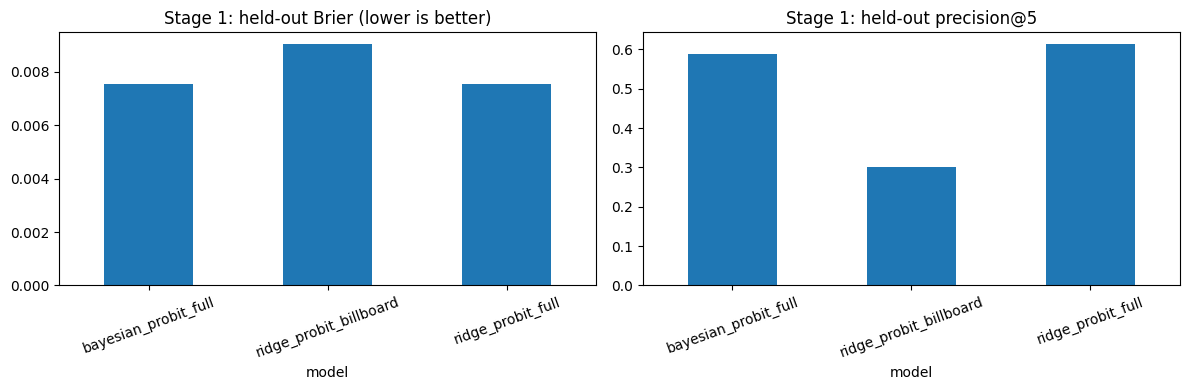

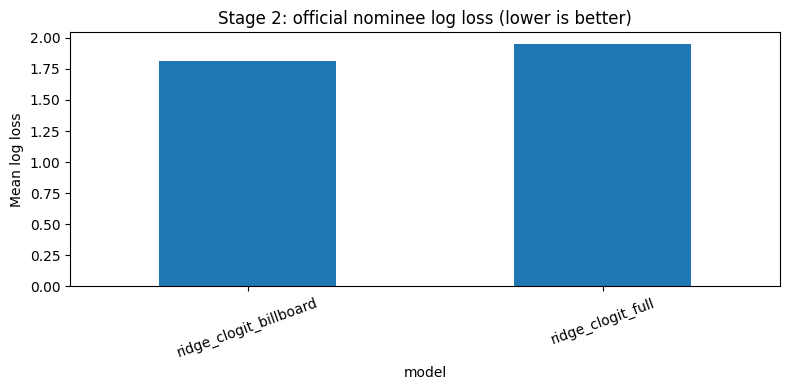

,ceremony_year,cat,model,title,performer,probability,actual_work,actual_artist,top1_correct,winner_covered
16,2025,album_of_the_year,ridge_clogit_billboard,THE TORTURED POETS DEPARTMENT,Taylor Swift,0.286121,COWBOY CARTER,Beyonce,False,True
17,2025,best_new_artist,ridge_clogit_billboard,Teddy Swims,Teddy Swims,0.236989,Chappell Roan,Chappell Roan,False,True
18,2025,music_video,ridge_clogit_billboard,Fortnight,Taylor Swift & Post Malone,0.393566,Not Like Us,Kendrick Lamar,False,False
19,2025,pop_duo_group,ridge_clogit_billboard,Fortnight,Taylor Swift & Post Malone,0.407495,Die With A Smile,Lady Gaga and Bruno Mars,False,True
20,2025,pop_solo,ridge_clogit_billboard,Down Bad,Taylor Swift,0.354248,Espresso,Sabrina Carpenter,False,False
21,2025,pop_vocal_album,ridge_clogit_billboard,THE TORTURED POETS DEPARTMENT,Taylor Swift,0.321069,Short n' Sweet,Sabrina Carpenter,False,False
22,2025,record_of_the_year,ridge_clogit_billboard,Fortnight,Taylor Swift & Post Malone,0.323604,Not Like Us,Kendrick Lamar,False,False
23,2025,song_of_the_year,ridge_clogit_billboard,Fortnight,Taylor Swift & Post Malone,0.248085,Not Like Us,Kendrick Lamar,False,False
24,2025,album_of_the_year,ridge_clogit_full,THE TORTURED POETS DEPARTMENT,Taylor Swift,0.354770,COWBOY CARTER,Beyonce,False,True
25,2025,best_new_artist,ridge_clogit_full,Teddy Swims,Teddy Swims,0.234340,Chappell Roan,Chappell Roan,False,True


,cat,model,title,performer,probability
328,album_of_the_year,ridge_clogit_billboard,The Life of a Showgirl,Taylor Swift,0.346290
332,best_new_artist,ridge_clogit_billboard,Malcolm Todd,Malcolm Todd,0.254906
337,music_video,ridge_clogit_billboard,The Fate of Ophelia,Taylor Swift,0.338854
341,pop_duo_group,ridge_clogit_billboard,The Life of a Showgirl,Taylor Swift & Sabrina Carpenter,0.321805
345,pop_solo,ridge_clogit_billboard,The Fate of Ophelia,Taylor Swift,0.303485
349,pop_vocal_album,ridge_clogit_billboard,The Life of a Showgirl,Taylor Swift,0.309193
353,record_of_the_year,ridge_clogit_billboard,The Fate of Ophelia,Taylor Swift,0.259103
358,song_of_the_year,ridge_clogit_billboard,The Fate of Ophelia,Taylor Swift,0.248162
363,album_of_the_year,ridge_clogit_full,petal,Ariana Grande,0.317854
367,best_new_artist,ridge_clogit_full,Malcolm Todd,Malcolm Todd,0.250557


In [ ]:
actual_events=history[history.season.isin(TEST_SEASONS)&history.winner.eq(1)][['season','cat','title','performer']]
if actual_events.duplicated(['season','cat']).any(): raise ValueError('Ambiguous actual winner category.')
actual_events=actual_events.rename(columns={'title':'actual_work','performer':'actual_artist'})
top=works[works.season.isin(TEST_SEASONS)&works.rank_in_category.eq(1)].copy()
top=top.merge(actual_events,on=['season','cat'],validate='many_to_one')
top=top.merge(scores2[['season','event_id','model','protocol','winner_covered','top1_correct']],
              on=['season','event_id','model','protocol'],validate='one_to_one')
top.to_csv(OUTPUT/'stage2_predictions_vs_actual.csv',index=False)
yearly1=scores1.groupby(['season','model'],as_index=False)[['brier','precision_at_5']].mean()
yearly1.to_csv(OUTPUT/'stage1_yearly_comparison.csv',index=False)
yearly2=scores2.groupby(['season','protocol','model'],as_index=False).agg(log_loss=('log_loss','mean'),
                                                                                     top1_hits=('top1_correct','sum'))
yearly2.to_csv(OUTPUT/'stage2_yearly_comparison.csv',index=False)
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(12,4))
agg=scores1.groupby('model')[['brier','precision_at_5']].mean()
agg.brier.plot.bar(ax=axes[0],title='Stage 1: held-out Brier (lower is better)',rot=20)
agg.precision_at_5.plot.bar(ax=axes[1],title='Stage 1: held-out precision@5',rot=20)
fig.tight_layout();fig.savefig(OUTPUT/'stage1_comparison.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(8,4))
scores2[scores2.protocol.eq('A_official_nominees')].groupby('model').log_loss.mean().plot.bar(ax=ax,rot=20)
ax.set(title='Stage 2: official nominee log loss (lower is better)',ylabel='Mean log loss')
fig.tight_layout();fig.savefig(OUTPUT/'stage2_comparison.png',dpi=160);plt.show()
display(top[top.protocol.eq('B_constructed_shortlist')][['ceremony_year','cat','model','title','performer',
                                                       'probability','actual_work','actual_artist','top1_correct','winner_covered']])
display(works[works.season.eq(FORECAST_SEASON)&works.rank_in_category.eq(1)][['cat','model','title','performer','probability']])

## 11. Save reproducibility record and download the result archive

The archive contains predictions, fitted point coefficients/scalers, tuning results, optimizer
diagnostics, historical comparisons, figures and metadata. It excludes copied input archives.
No future labels, unsupported unconditional win probabilities, or fabricated results are added.

Limits retained from the original project: retrospective source construction; original known
nomination-label errors and Silk Sonic identity issues; incomplete pool/catalog and release
eligibility proxies; only two test ceremonies; conditional independence of category outcomes;
transferring a winner model trained on official nominees to constructed shortlists.

Stage 1 hit tables list actual nominees inside the original labelled pool, not a full audited
official nominee list. Stage 2/3 candidate coverage is unchanged by construction. New Stage 1
rankings do NOT feed new work sets into this notebook; an end-to-end rerun requires new curation.

References: course syllabus Week 3 (Ridge and choice models); Train, *Discrete Choice Methods
with Simulation*, 2nd ed., https://eml.berkeley.edu/books/choice2.html ; Brier (1950);
Gneiting & Raftery (2007), *Strictly Proper Scoring Rules, Prediction, and Estimation*.
AI assistance: ChatGPT helped implement and explain this notebook; the team is responsible
for reviewing code, inputs, execution diagnostics, interpretation and submitted results.

In [ ]:
metadata=dict(created_at_utc=datetime.now(timezone.utc).isoformat(),model_version=MODEL_VERSION,
              data_sha256=DATA_SHA256,input_hashes=INPUT_HASHES,stage1_reference=STAGE1_MANIFEST,
              bayesian_stage23_reference_loaded=BAYES is not None,test_seasons=TEST_SEASONS,
              tuning_seasons=TUNE_SEASONS,forecast_season=FORECAST_SEASON,ceremony_year=2027,
              lambda_grid=LAMBDA_GRID,selected_stage1=PENALTY1,selected_stage2=PENALTY2,
              stage1_features=NAMES1,stage2_features=NAMES2,
              penalty_convention='negative SUM log likelihood + lambda/2 * squared slope norm; no intercept penalty',
              stage2_protocol='frozen input work sets for every model; no end-to-end shortlist rebuild',
              count_uncertainty='classical plug-in: outcome uncertainty only; Bayes: saved posterior mixture',
              versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__},
              training_run_by='user when executing this notebook')
(OUTPUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
shutil.copyfile(INPUT/'forecast_choices.csv',OUTPUT/'used_work_choices.csv')
shutil.copyfile(INPUT/'omitted_artist_choices.csv',OUTPUT/'omitted_artist_choices.csv')
archive=ROOT/f'grammy_nonbayesian_results_{RUN_ID}.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUTPUT.rglob('*'):
        if p.is_file() and 'extracted_inputs' not in p.relative_to(OUTPUT).parts:
            z.write(p,p.relative_to(OUTPUT))
print('Results archive:',archive)
display(FileLink(str(archive)))
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Kaggle: download the ZIP from the Output panel. CPU is sufficient.')

Results archive: /kaggle/working/grammy_nonbayesian_results_20261101T145700256257.zip


/kaggle/working/grammy_nonbayesian_results_20261101T145700256257.zip

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("STAGE 1: прогноз номинантов Grammy 2027")
with pd.option_context("display.max_rows", 100):
    display(
        pred1[
            pred1.season.eq(FORECAST_SEASON)
            & pred1.model.eq("ridge_probit_full")
            & pred1.rank_in_category.le(5)
        ][["cat", "artist", "probability"]]
    )

print("STAGE 2: наиболее вероятные победители Grammy 2027")
display(
    works[
        works.season.eq(FORECAST_SEASON)
        & works.model.eq("ridge_clogit_billboard")
        & works.rank_in_category.eq(1)
    ][["cat", "title", "performer", "probability"]]
)

print("STAGE 3: прогноз числа побед Grammy 2027")
display(
    counts[
        counts.season.eq(FORECAST_SEASON)
        & counts.model.eq("ridge_clogit_billboard")
    ].sort_values("expected_awards", ascending=False)[
        ["artist", "expected_awards", "p_at_least_one",
         "p_at_least_two", "prediction_set_90"]
    ]
)

STAGE 1: прогноз номинантов Grammy 2027


,cat,artist,probability
26695,album_of_the_year,Taylor Swift,0.730738
26588,album_of_the_year,Olivia Dean,0.532559
26653,album_of_the_year,Sabrina Carpenter,0.518019
26160,album_of_the_year,Ariana Grande,0.472325
26222,album_of_the_year,BTS,0.470527
28587,best_new_artist,Sienna Spiro,0.357051
28220,best_new_artist,Ella Langley,0.293909
28596,best_new_artist,STELLA LEFTY,0.224261
28470,best_new_artist,Morgan Wallen,0.194761
28431,best_new_artist,Malcolm Todd,0.186985


STAGE 2: наиболее вероятные победители Grammy 2027


,cat,title,performer,probability
328,album_of_the_year,The Life of a Showgirl,Taylor Swift,0.346290
332,best_new_artist,Malcolm Todd,Malcolm Todd,0.254906
337,music_video,The Fate of Ophelia,Taylor Swift,0.338854
341,pop_duo_group,The Life of a Showgirl,Taylor Swift & Sabrina Carpenter,0.321805
345,pop_solo,The Fate of Ophelia,Taylor Swift,0.303485
349,pop_vocal_album,The Life of a Showgirl,Taylor Swift,0.309193
353,record_of_the_year,The Fate of Ophelia,Taylor Swift,0.259103
358,song_of_the_year,The Fate of Ophelia,Taylor Swift,0.248162


STAGE 3: прогноз числа побед Grammy 2027


,artist,expected_awards,p_at_least_one,p_at_least_two,prediction_set_90
182,Taylor Swift,2.582417,0.962084,0.800633,"[1, 2, 3, 4, 5]"
166,Ariana Grande,1.294530,0.776633,0.385977,"[0, 1, 2, 3]"
179,Sabrina Carpenter,0.993307,0.682921,0.258049,"[0, 1, 2]"
174,Lady Gaga,0.666997,0.530180,0.125974,"[0, 1, 2]"
169,BTS,0.536330,0.446182,0.084439,"[0, 1]"
177,Olivia Dean,0.489945,0.415093,0.070640,"[0, 1]"
178,Olivia Rodrigo,0.439052,0.390865,0.048188,"[0, 1]"
172,Ella Langley,0.407769,0.368336,0.039433,"[0, 1]"
168,Bruno Mars,0.395131,0.356117,0.039014,"[0, 1]"
170,Cynthia Erivo,0.256566,0.256566,0.000000,"[0, 1]"


In [ ]:

import json, shutil
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd

if MODEL_VERSION != 'classical-ridge-probit-clogit-v1':
    raise ValueError('Use grammy_nonbayesian_stages123, not a Bayesian or Billboard-baseline notebook.')
NB_YEARS=list(range(2018,2026))
NB_TUNE=[2016,2017]
NB_GRID=[0.1,1.0,10.0]
GRAD_TOL=1e-3
NB_ORIGINAL_OUTPUT=OUTPUT
NB_ORIGINAL_FIT_LOG=FIT_LOG
stamp=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
NB_OUT=Path(NB_ORIGINAL_OUTPUT)/('expanded_nonbayesian_'+stamp)
NB_OUT.mkdir(parents=True,exist_ok=True)

def run_expanded_nonbayes():
    global OUTPUT,FIT_LOG
    OUTPUT=NB_OUT;FIT_LOG=[]
    try:
        tune1,tune2=[],[]
        for variant in VARIANTS1:
            for lam in NB_GRID:
                for season in NB_TUNE:
                    for cat in CATEGORIES:
                        tm=(data.season.lt(season)&data.cat.eq(cat)).to_numpy()
                        vm=(data.season.eq(season)&data.cat.eq(cat)).to_numpy()
                        b,s=fit1(tm,variant,lam,f'expanded_tune1_{variant}_{lam}_{season}_{cat}')
                        p=predict1(vm,variant,b,s)
                        tune1.append(dict(variant=variant,penalty=lam,season=season,cat=cat,
                            brier=float(np.mean((p-data.loc[vm,'nominated'].to_numpy())**2))))
                print('Expanded Stage 1 tuning:',variant,lam,flush=True)
        for variant in VARIANTS2:
            for lam in NB_GRID:
                for season in NB_TUNE:
                    tm=history.season.lt(season).to_numpy();vm=history.season.eq(season).to_numpy()
                    tr=history.loc[tm].reset_index(drop=True);va=history.loc[vm].reset_index(drop=True)
                    b,s=fit2(tr,XH[tm],variant,lam,f'expanded_tune2_{variant}_{lam}_{season}')
                    p=choice_logps(va,apply_scaler(XH[vm][:,VARIANTS2[variant]],s),b)
                    tune2.append(dict(variant=variant,penalty=lam,season=season,log_loss=float(mean_event_loss(p))))
                print('Expanded Stage 2 tuning:',variant,lam,flush=True)
        tuning1=pd.DataFrame(tune1);tuning2=pd.DataFrame(tune2)
        tuning1.to_csv(NB_OUT/'stage1_tuning_2016_2017.csv',index=False)
        tuning2.to_csv(NB_OUT/'stage2_tuning_2016_2017.csv',index=False)
        def choose(t,metric):
            sel=t.groupby(['variant','penalty'],as_index=False)[metric].mean()
            sel=sel.sort_values(['variant',metric,'penalty'],ascending=[True,True,False]).drop_duplicates('variant')
            return dict(zip(sel.variant,sel.penalty))
        penalty1=choose(tuning1,'brier');penalty2=choose(tuning2,'log_loss')
        print('Frozen Stage 1 penalties:',penalty1,'| Stage 2:',penalty2)
        p1parts,score1,wparts,cparts,pparts,score2=[],[],[],[],[],[]
        for season in NB_YEARS:
            for variant in VARIANTS1:
                for cat in CATEGORIES:
                    tm=(data.season.lt(season)&data.cat.eq(cat)).to_numpy()
                    vm=(data.season.eq(season)&data.cat.eq(cat)).to_numpy()
                    b,s=fit1(tm,variant,float(penalty1[variant]),f'expanded_fit1_{variant}_{season}_{cat}')
                    out=data.loc[vm,KEYS+['artist','nominated']].copy()
                    out['probability']=predict1(vm,variant,b,s)
                    out['model']='ridge_probit_'+variant
                    out=out.sort_values(['probability','artist_key'],ascending=[False,True])
                    out['rank_in_category']=np.arange(1,len(out)+1)
                    out['model_version']=MODEL_VERSION;out['data_sha256']=DATA_SHA256
                    p1parts.append(out)
                    top=out.head(TOP_K)
                    score1.append(dict(season=season,cat=cat,model='ridge_probit_'+variant,
                        brier=float(np.mean((out.probability-out.nominated)**2)),
                        precision_at_5=float(top.nominated.mean()),hits=int(top.nominated.sum())))
                    save_fit(f'expanded_stage1_{variant}_{season}_{cat}',b,s,penalty=float(penalty1[variant]),
                        season=season,cat=cat,features=['intercept']+[NAMES1[k] for k in VARIANTS1[variant]],data_sha256=DATA_SHA256)
            tm=history.season.lt(season).to_numpy();om=history.season.eq(season).to_numpy()
            tr=history.loc[tm].reset_index(drop=True);off=history.loc[om].reset_index(drop=True)
            if off.event_id.nunique()!=8 or set(off.cat)!=set(CATEGORIES): raise ValueError('Need eight official events.')
            actual=actual_counts(off)
            for variant in VARIANTS2:
                model='ridge_clogit_'+variant;lam=float(penalty2[variant])
                b,s=fit2(tr,XH[tm],variant,lam,f'expanded_fit2_{variant}_{season}')
                pred=choice_logps(off,apply_scaler(XH[om][:,VARIANTS2[variant]],s),b)
                wt=work_table(pred,model,season,'A_official_nominees');wparts.append(wt)
                pm,cs=count_tables(pred,model,season,'A_official_nominees',actual)
                cparts.append(cs);pparts.append(pm)
                for event,g in wt.groupby('event_id'):
                    win=g[g.winner.eq(1)]
                    if len(win)!=1: raise ValueError('Missing official winner.')
                    top=g[g.rank_in_category.eq(1)].iloc[0]
                    score2.append(dict(season=season,cat=top['cat'],event_id=event,model=model,
                        protocol='A_official_nominees',K=len(g),log_score=float(win.log_probability.iloc[0]),
                        log_loss=-float(win.log_probability.iloc[0]),top1_correct=bool(top.winner==1),
                        predicted_work=top.title,predicted_artist=top.performer,
                        actual_work=win.title.iloc[0],actual_artist=win.performer.iloc[0]))
                save_fit(f'expanded_stage2_{variant}_{season}',b,s,penalty=lam,season=season,
                         features=[NAMES2[k] for k in VARIANTS2[variant]],input_hashes=INPUT_HASHES)
            # Checkpoints are saved after every complete season.
            pd.concat(p1parts,ignore_index=True).to_csv(NB_OUT/'stage1_predictions_2018_2025.csv.gz',index=False)
            pd.DataFrame(score1).to_csv(NB_OUT/'stage1_scores_2018_2025.csv',index=False)
            pd.DataFrame(score2).to_csv(NB_OUT/'stage2_scores_2018_2025.csv',index=False)
            pd.concat(wparts,ignore_index=True).to_csv(NB_OUT/'stage2_work_probabilities_2018_2025.csv',index=False)
            pd.concat(cparts,ignore_index=True).to_csv(NB_OUT/'stage3_scores_2018_2025.csv',index=False)
            pd.concat(pparts,ignore_index=True).to_csv(NB_OUT/'stage3_pmfs_2018_2025.csv',index=False)
            print('Expanded non-Bayesian tests complete:',season,flush=True)
        s1=pd.DataFrame(score1);s2=pd.DataFrame(score2);s3=pd.concat(cparts,ignore_index=True)
        if len(s1)!=128 or len(s2)!=128: raise ValueError('Incomplete eight-season evaluation.')
        display(s1.groupby('model').agg(brier=('brier','mean'),precision_at_5=('precision_at_5','mean'),hits=('hits','sum')))
        display(s2.groupby('model').agg(log_loss=('log_loss','mean'),top1_hits=('top1_correct','sum'),events=('top1_correct','size')))
        display(s3.groupby('model').agg(count_log_score=('count_log_score','mean'),
            mean_absolute_error=('absolute_error','mean'),coverage_90=('covered_90','mean')))
        s1.groupby(['season','model'],as_index=False)[['brier','precision_at_5']].mean().to_csv(NB_OUT/'stage1_yearly_scores.csv',index=False)
        s2.groupby(['season','model'],as_index=False).agg(log_loss=('log_loss','mean'),top1_hits=('top1_correct','sum')).to_csv(NB_OUT/'stage2_yearly_scores.csv',index=False)
        s3.groupby(['season','model'],as_index=False).agg(count_log_score=('count_log_score','mean'),
            mean_absolute_error=('absolute_error','mean'),coverage_90=('covered_90','mean')).to_csv(NB_OUT/'stage3_yearly_scores.csv',index=False)
        (NB_OUT/'run_metadata.json').write_text(json.dumps(dict(model_version=MODEL_VERSION,
            experiment='expanded-2018-2025-frozen-early-tuning-v1',test_seasons=NB_YEARS,tuning_seasons=NB_TUNE,
            selected_stage1=penalty1,selected_stage2=penalty2,lambda_grid=NB_GRID,
            data_sha256=DATA_SHA256,input_hashes=INPUT_HASHES,gradient_tolerance=GRAD_TOL,
            stage1_features=NAMES1,stage2_features=NAMES2,
            scope='Stage 1 artist pool; Stage 2/3 official nominees only; original data',
            penalty_convention='negative SUM log likelihood + lambda/2 * squared slope norm; unpenalized intercept',
            counts='Fixed fitted parameters; outcome uncertainty; no bootstrap',
            versions={'numpy':np.__version__,'pandas':pd.__version__},
            limitations=['Retrospective data','Original label and identity issues','Eight dependent annual occasions']),indent=2))
    finally:
        OUTPUT=NB_ORIGINAL_OUTPUT;FIT_LOG=NB_ORIGINAL_FIT_LOG
    archive=shutil.make_archive(str(NB_OUT),'zip',root_dir=NB_OUT)
    print('Download from Kaggle Output:',archive)

run_expanded_nonbayes()

Expanded Stage 1 tuning: billboard 0.1
Expanded Stage 1 tuning: billboard 1.0
Expanded Stage 1 tuning: billboard 10.0
Expanded Stage 1 tuning: full 0.1
Expanded Stage 1 tuning: full 1.0
Expanded Stage 1 tuning: full 10.0
Expanded Stage 2 tuning: billboard 0.1
Expanded Stage 2 tuning: billboard 1.0
Expanded Stage 2 tuning: billboard 10.0
Expanded Stage 2 tuning: full 0.1
Expanded Stage 2 tuning: full 1.0
Expanded Stage 2 tuning: full 10.0
Frozen Stage 1 penalties: {'billboard': 10.0, 'full': 10.0} | Stage 2: {'billboard': 0.1, 'full': 0.1}
Expanded non-Bayesian tests complete: 2018
Expanded non-Bayesian tests complete: 2019
Expanded non-Bayesian tests complete: 2020
Expanded non-Bayesian tests complete: 2021
Expanded non-Bayesian tests complete: 2022
Expanded non-Bayesian tests complete: 2023
Expanded non-Bayesian tests complete: 2024
Expanded non-Bayesian tests complete: 2025


,brier,precision_at_5,hits
model,,,
ridge_probit_billboard,0.008686,0.275,88
ridge_probit_full,0.007750,0.475,152


,log_loss,top1_hits,events
model,,,
ridge_clogit_billboard,1.919258,9,64
ridge_clogit_full,2.056757,11,64


,count_log_score,mean_absolute_error,coverage_90
model,,,
ridge_clogit_billboard,-0.610585,0.369754,0.962547
ridge_clogit_full,-0.646485,0.376392,0.947566


Download from Kaggle Output: /kaggle/working/grammy_nonbayesian_results/20261101T145700256257/expanded_nonbayesian_20261101T145803773216.zip
